# **Final project**

In [2]:
from google.colab import files
uploaded = files.upload()

Saving chronic_kidney_disease.arff to chronic_kidney_disease (1).arff


In [3]:
import pandas as pd

cols = ['age','bp','sg','al','su','rbc','pc','pcc','ba','bgr','bu','sc',
        'sod','pot','hemo','pcv','wbcc','rbcc','htn','dm','cad','appet',
        'pe','ane','class']

rows = []
with open('chronic_kidney_disease.arff') as f:
    for line in f:
        line = line.strip()
        if line and not line.startswith(('@', '%')):
            values = [v.strip() for v in line.split(',') if v.strip() != '']
            rows.append(values)

In [4]:
df = pd.DataFrame(rows, columns=cols)

In [5]:
df = df.replace('?', pd.NA)

In [6]:
df.to_csv('ckd.csv', index=False)

print(df.shape)

(400, 25)


In [7]:
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48,80,1.020,1,0,<NA>,normal,notpresent,notpresent,121,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7,50,1.020,4,0,<NA>,normal,notpresent,notpresent,<NA>,...,38,6000,<NA>,no,no,no,good,no,no,ckd
2,62,80,1.010,2,3,normal,normal,notpresent,notpresent,423,...,31,7500,<NA>,no,yes,no,poor,no,yes,ckd
3,48,70,1.005,4,0,normal,abnormal,present,notpresent,117,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51,80,1.010,2,0,normal,normal,notpresent,notpresent,106,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   age     391 non-null    object
 1   bp      388 non-null    object
 2   sg      353 non-null    object
 3   al      354 non-null    object
 4   su      351 non-null    object
 5   rbc     248 non-null    object
 6   pc      335 non-null    object
 7   pcc     396 non-null    object
 8   ba      396 non-null    object
 9   bgr     356 non-null    object
 10  bu      381 non-null    object
 11  sc      383 non-null    object
 12  sod     313 non-null    object
 13  pot     312 non-null    object
 14  hemo    348 non-null    object
 15  pcv     329 non-null    object
 16  wbcc    294 non-null    object
 17  rbcc    269 non-null    object
 18  htn     398 non-null    object
 19  dm      398 non-null    object
 20  cad     398 non-null    object
 21  appet   399 non-null    object
 22  pe      399 non-null    ob

In [9]:
df.describe()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
count,391,388,353,354,351,248,335,396,396,356,...,329,294,269,398,398,398,399,399,399,400
unique,76,10,5,6,6,2,2,2,2,146,...,42,89,48,2,2,2,2,2,2,2
top,60,80,1.020,0,0,normal,normal,notpresent,notpresent,99,...,41,9800,5.2,no,no,no,good,no,no,ckd
freq,19,116,106,199,290,201,259,354,374,10,...,21,11,18,251,261,364,317,323,339,250


In [10]:
df.isnull().sum()

,0
age,9
bp,12
sg,47
al,46
su,49
rbc,152
pc,65
pcc,4
ba,4
bgr,44


In [11]:
df['class'].value_counts()

,count
class,
ckd,250
notckd,150


# **Data Visualization**

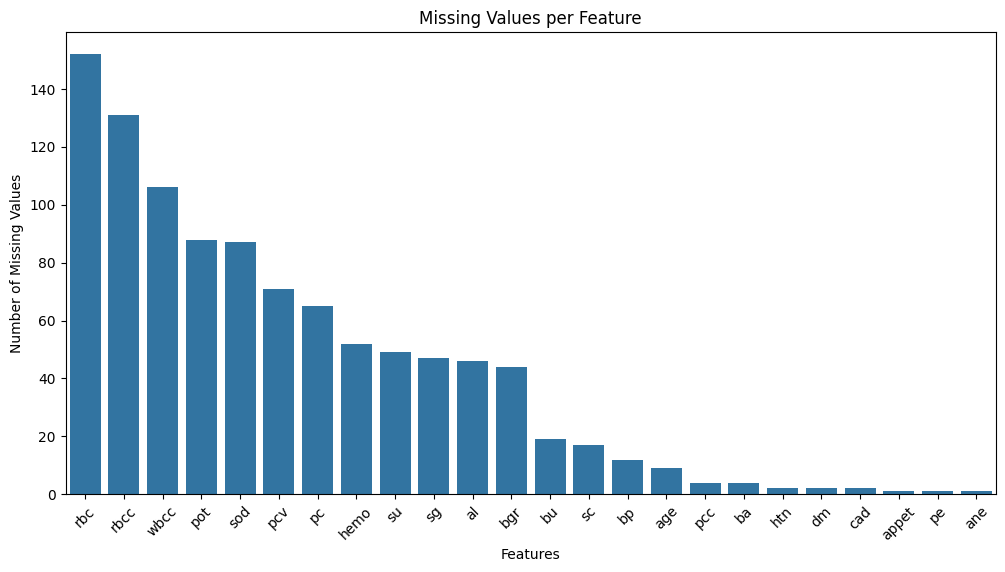

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing.index,
    y=missing.values
)

plt.xticks(rotation=45)
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.title("Missing Values per Feature")

plt.show()

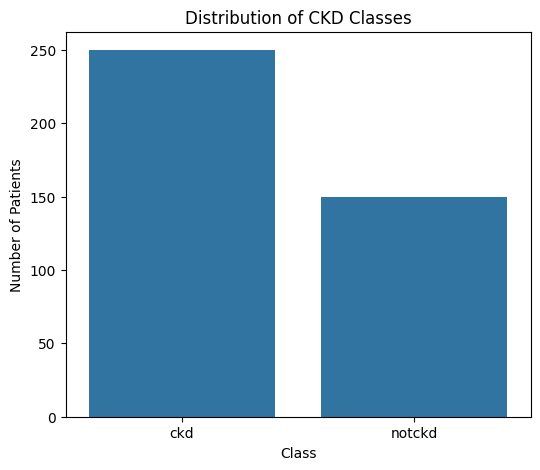

In [13]:
plt.figure(figsize=(6, 5))

sns.countplot(data=df, x='class')

plt.xlabel("Class")
plt.ylabel("Number of Patients")
plt.title("Distribution of CKD Classes")

plt.show()

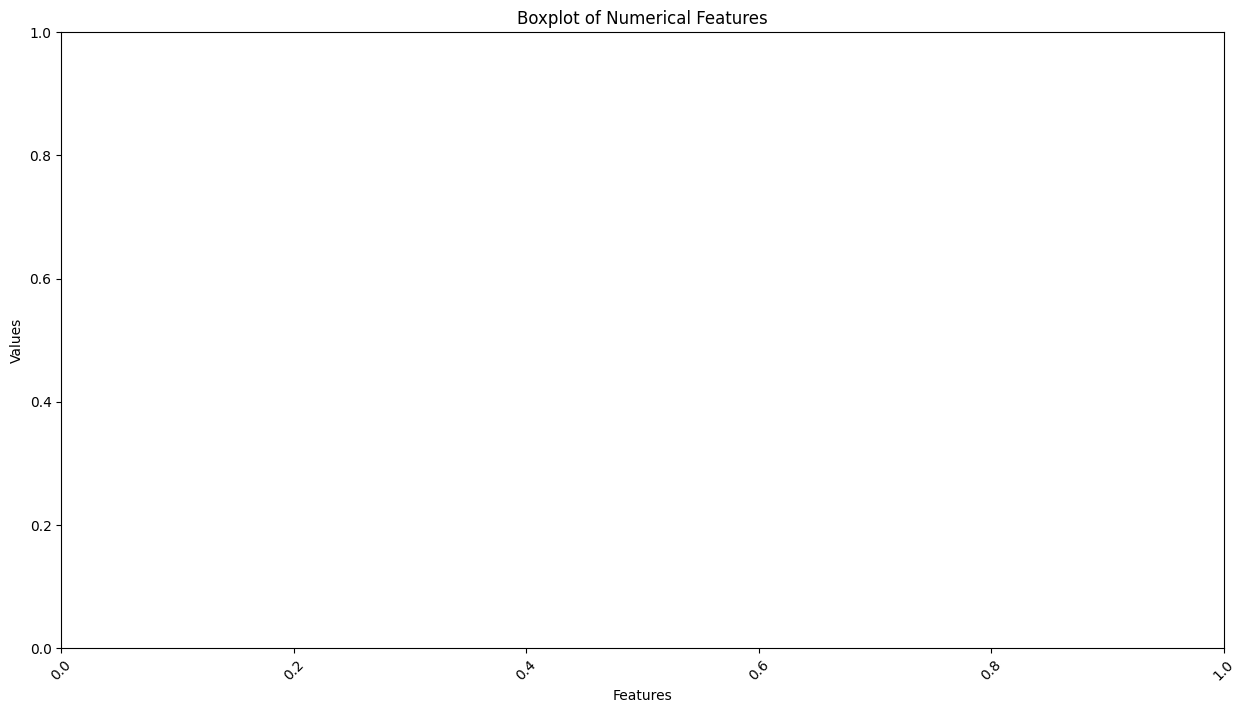

In [14]:
numeric_cols = ['age','bp','sg','al','su','bgr','bu','sc',
                'sod','pot','hemo','pcv','wbcc','rbcc']

plt.figure(figsize=(15, 8))

sns.boxplot(data=df[numeric_cols])

plt.xticks(rotation=45)
plt.title("Boxplot of Numerical Features")
plt.xlabel("Features")
plt.ylabel("Values")

plt.show()

In [15]:
numeric_cols = ['age','bp','sg','al','su','bgr','bu','sc',
                'sod','pot','hemo','pcv','wbcc','rbcc']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(df[numeric_cols].dtypes)

age     float64
bp      float64
sg      float64
al      float64
su      float64
bgr     float64
bu      float64
sc      float64
sod     float64
pot     float64
hemo    float64
pcv     float64
wbcc    float64
rbcc    float64
dtype: object


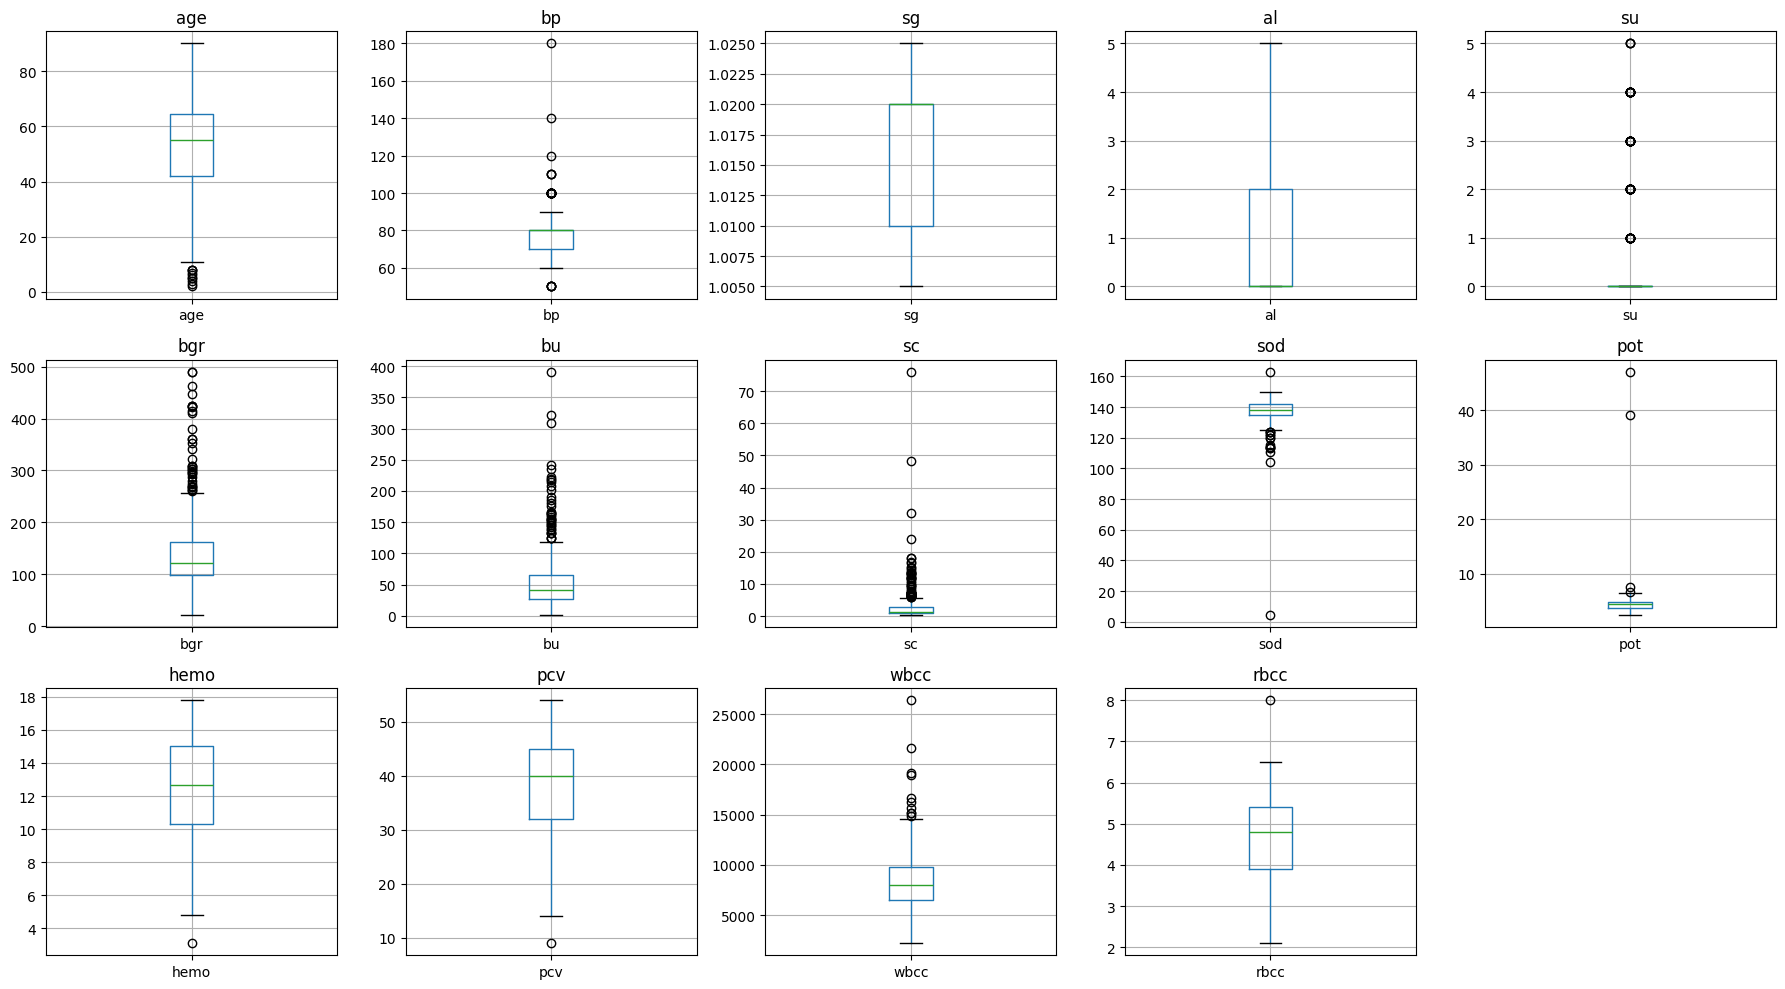

In [16]:
fig ,axes = plt.subplots(3, 5, figsize=(18, 10))

for ax, col in zip(axes.flatten(), numeric_cols):
    df.boxplot(column=col, ax=ax)
    ax.set_title(col)

axes.flatten()[-1].axis('off')

plt.tight_layout()
plt.show()

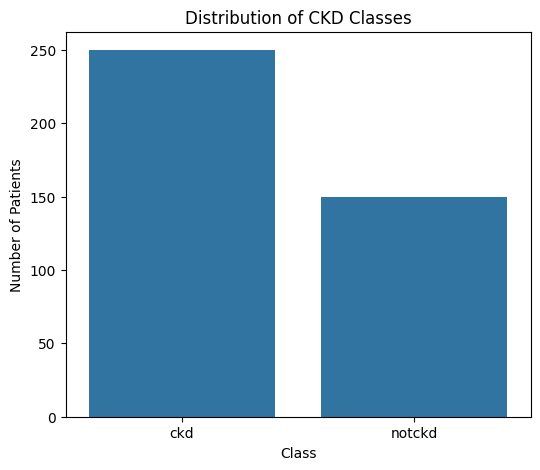

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.countplot(data=df, x='class')

plt.title('Distribution of CKD Classes')
plt.xlabel('Class')
plt.ylabel('Number of Patients')

plt.show()

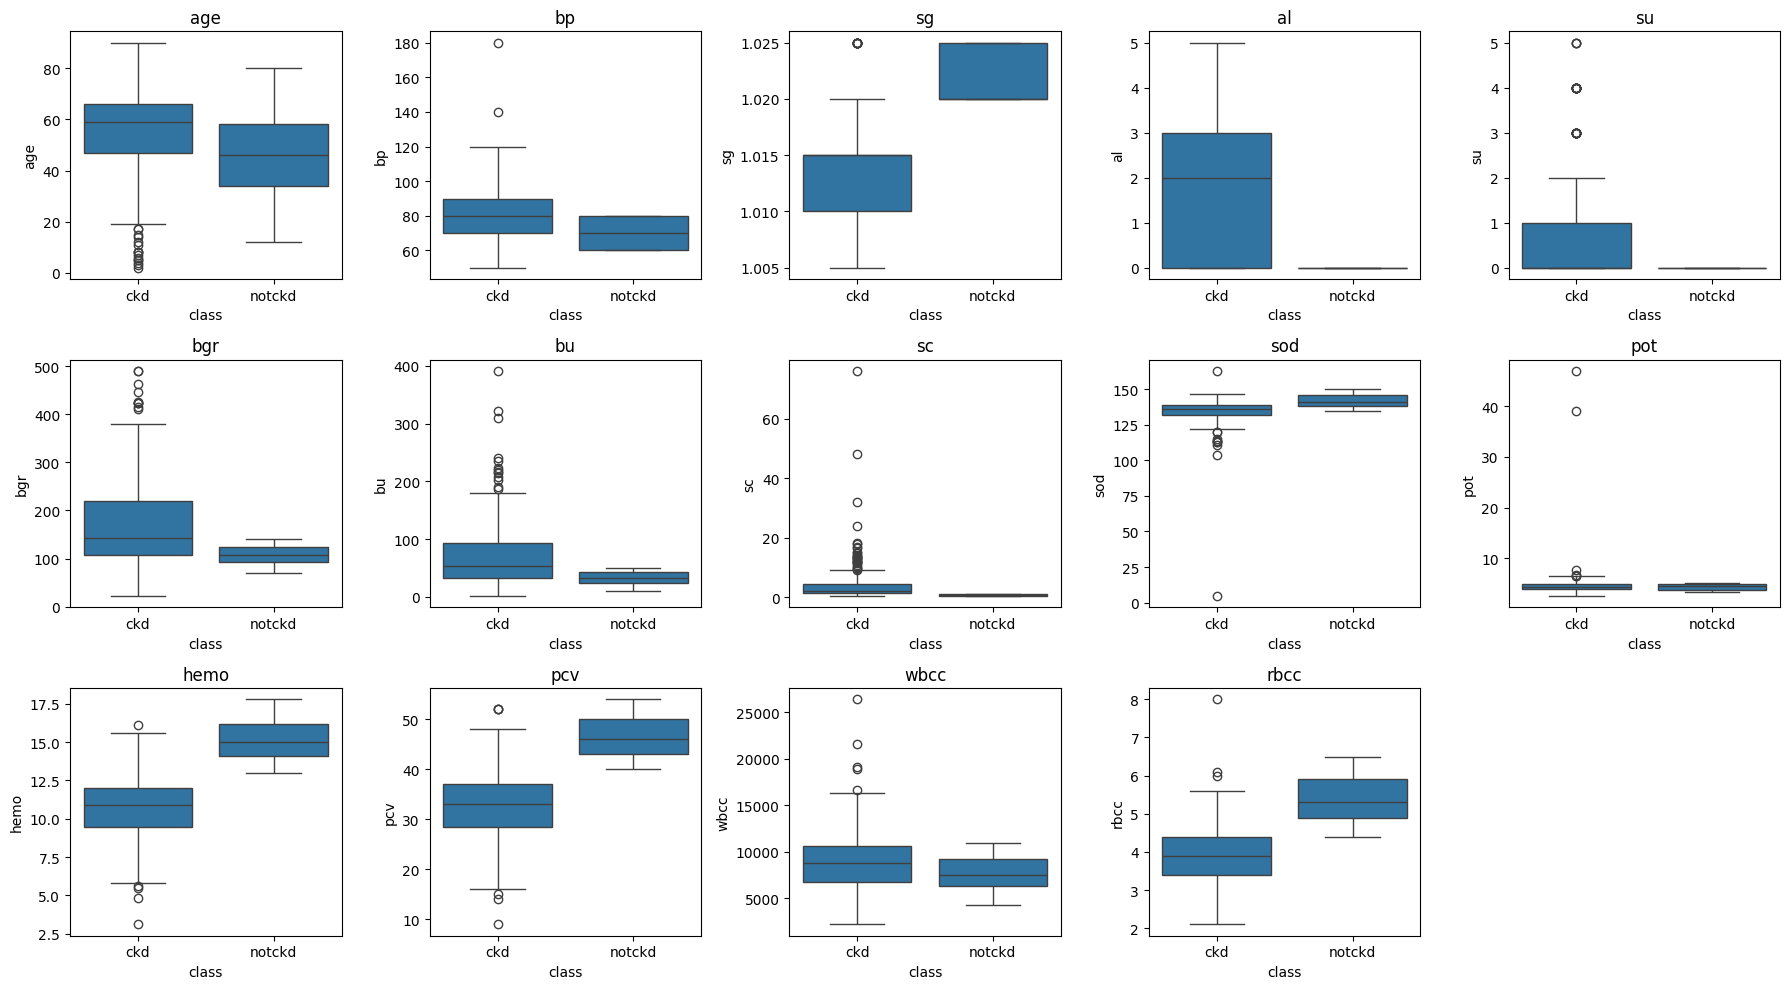

In [18]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(data=df, x='class', y=col, ax=ax)
    ax.set_title(col)

axes.flatten()[-1].axis('off')

plt.tight_layout()
plt.show()

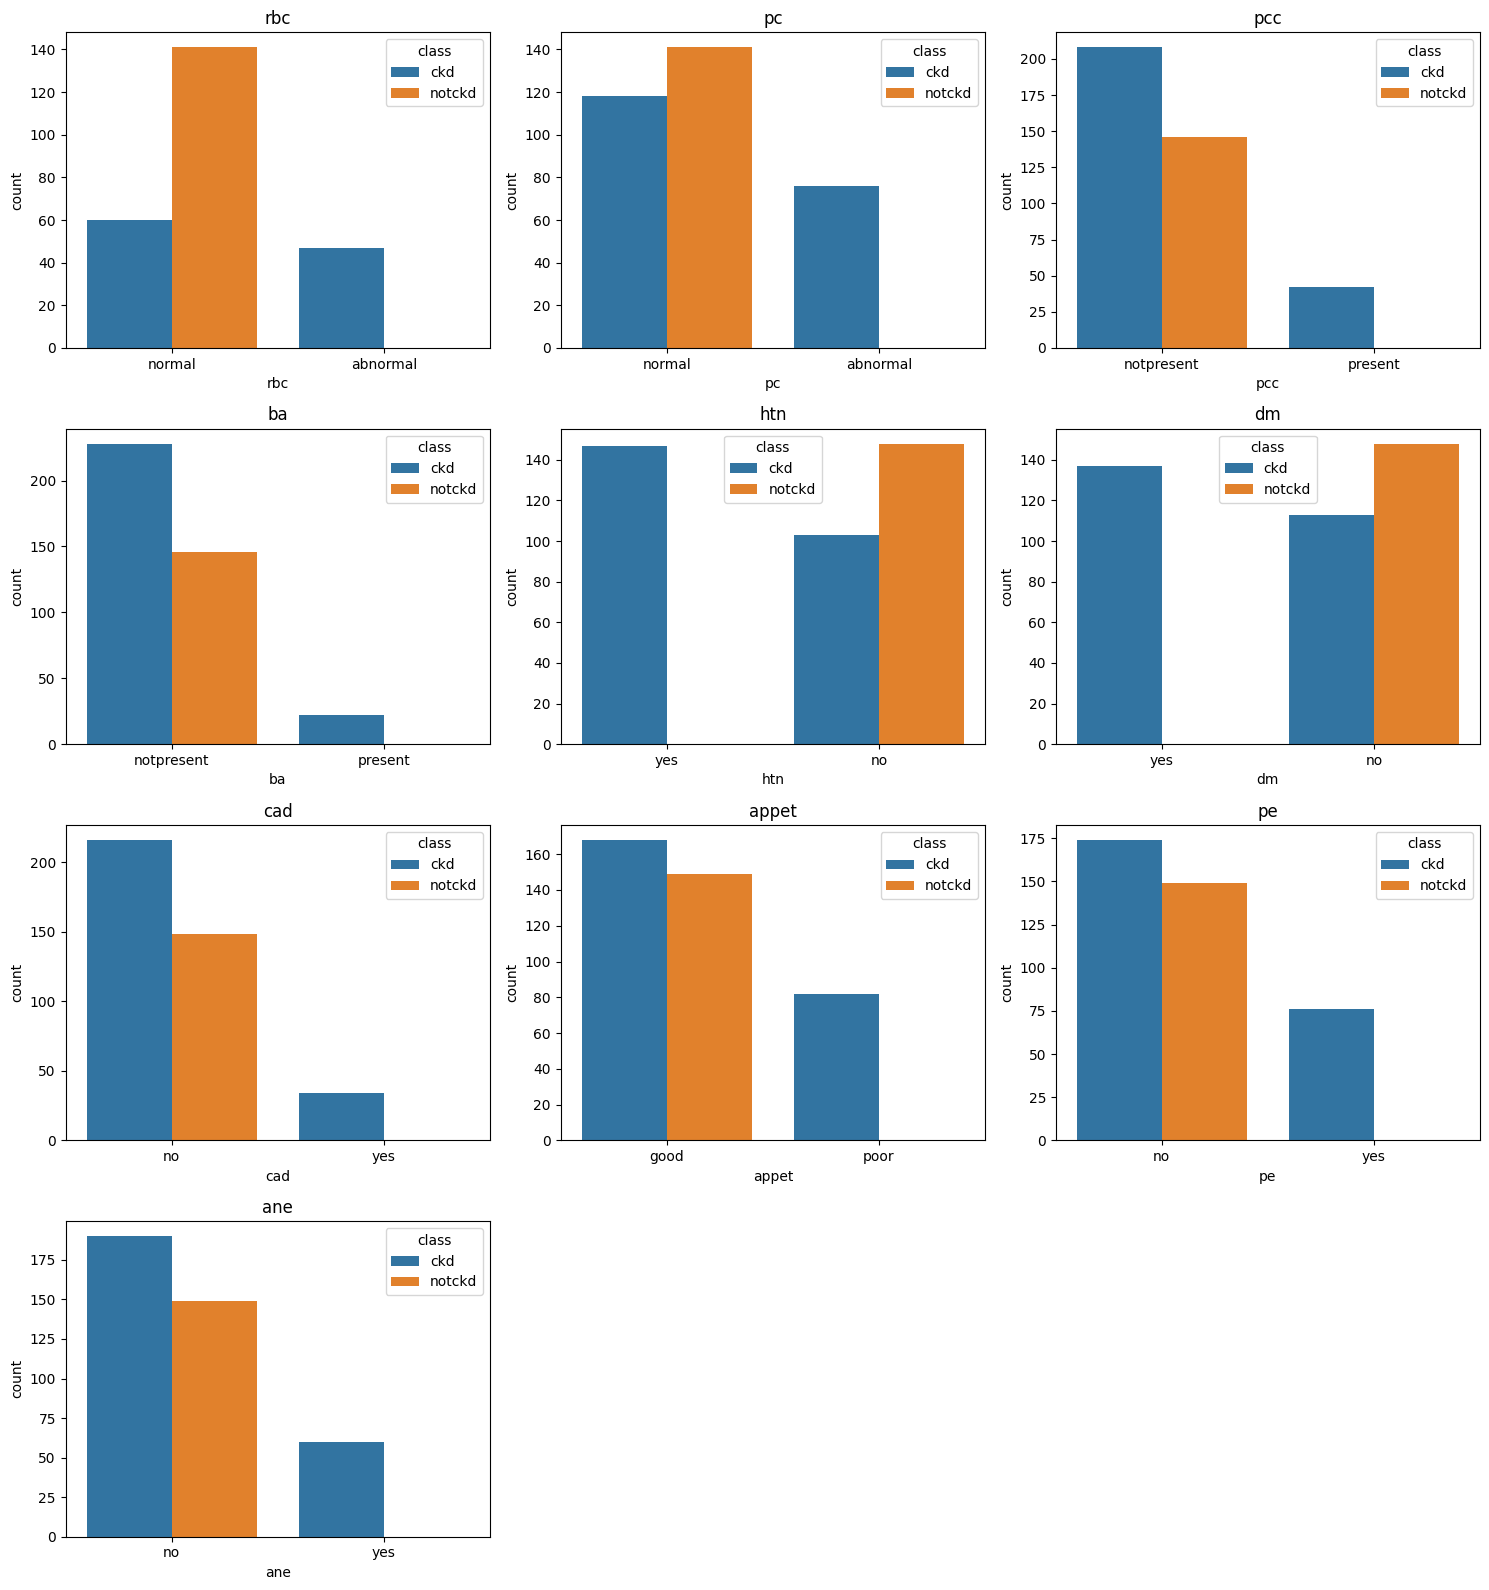

In [19]:
categorical_cols = ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad',
                    'appet', 'pe', 'ane']

fig, axes = plt.subplots(4, 3, figsize=(15, 16))

for ax, col in zip(axes.flatten(), categorical_cols):
    sns.countplot(data=df, x=col, hue='class', ax=ax)
    ax.set_title(col)

for ax in axes.flatten()[len(categorical_cols):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

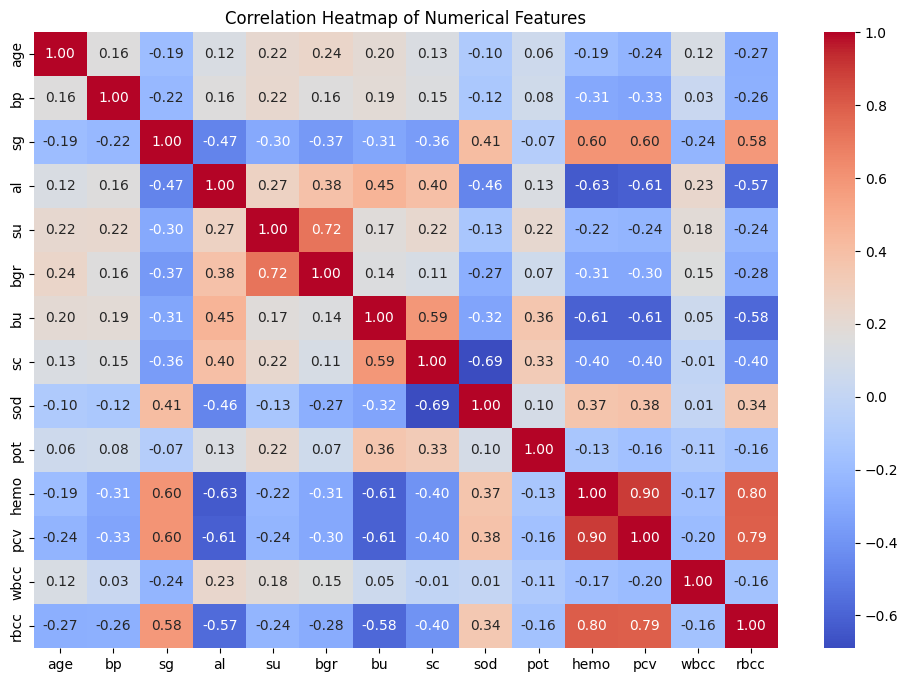

In [20]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

**Train-Test-Split**

In [21]:
from sklearn.model_selection import train_test_split

X = df.drop('class', axis=1)
y = df['class']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (320, 24)
X_test shape: (80, 24)
y_train shape: (320,)
y_test shape: (80,)


In [22]:
X_train.isnull().sum()

,0
age,5
bp,10
sg,33
al,34
su,36
rbc,127
pc,49
pcc,4
ba,4
bgr,38


In [23]:
X_test.isnull().sum()

,0
age,4
bp,2
sg,14
al,12
su,13
rbc,25
pc,16
pcc,0
ba,0
bgr,6


**Handling Missing Values (numerical)**

In [24]:
for col in numeric_cols:
    X_train[col] = X_train[col].fillna(X_train[col].median())
    X_test[col] = X_test[col].fillna(X_train[col].median())

**Handling Missing Values (Categorical)**

In [25]:
for col in categorical_cols:
    X_train[col] = X_train[col].fillna(X_train[col].mode()[0])
    X_test[col] = X_test[col].fillna(X_train[col].mode()[0])

**Checking**

In [26]:
print("Missing values in X_train:")
print(X_train.isnull().sum().sum())

print("Missing values in X_test:")
print(X_test.isnull().sum().sum())

Missing values in X_train:
0
Missing values in X_test:
0


**transforming gactegorical features into numerical valuse that models can deal with**

In [27]:
from sklearn.preprocessing import LabelEncoder

for col in categorical_cols:
    le = LabelEncoder()

    X_train[col] = le.fit_transform(X_train[col])
    X_test[col] = le.transform(X_test[col])

In [28]:
print(X_train[categorical_cols].dtypes)

rbc      int64
pc       int64
pcc      int64
ba       int64
htn      int64
dm       int64
cad      int64
appet    int64
pe       int64
ane      int64
dtype: object


**Scaling**

In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

**using stander scaler on numerical values only because Ml algorithms can influence by features ranges and we do not use it on categorical because we did encoding and it already became in the range 0 , 1**

# **Classification Algorithms**

**Logistic Regression**

In [30]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='ckd'))
print("Recall:", recall_score(y_test, y_pred, pos_label='ckd'))
print("F1 Score:", f1_score(y_test, y_pred, pos_label='ckd'))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [32]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[50  0]
 [ 0 30]]


**KNN**

In [33]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, pos_label='ckd'))
print("Recall:", recall_score(y_test, y_pred_knn, pos_label='ckd'))
print("F1 Score:", f1_score(y_test, y_pred_knn, pos_label='ckd'))

Accuracy: 0.9625
Precision: 1.0
Recall: 0.94
F1 Score: 0.9690721649484536


**Decision Tree**

In [35]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

In [36]:
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, pos_label='ckd'))
print("Recall:", recall_score(y_test, y_pred_dt, pos_label='ckd'))
print("F1 Score:", f1_score(y_test, y_pred_dt, pos_label='ckd'))

Accuracy: 0.975
Precision: 0.9615384615384616
Recall: 1.0
F1 Score: 0.9803921568627451


**Random Forest**

In [37]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [38]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, pos_label='ckd'))
print("Recall:", recall_score(y_test, y_pred_rf, pos_label='ckd'))
print("F1 Score:", f1_score(y_test, y_pred_rf, pos_label='ckd'))

Accuracy: 0.975
Precision: 0.9615384615384616
Recall: 1.0
F1 Score: 0.9803921568627451


**Support Vector Machine (SVM)**

In [39]:
from sklearn.svm import SVC

svm_model = SVC()

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

In [40]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, pos_label='ckd'))
print("Recall:", recall_score(y_test, y_pred_svm, pos_label='ckd'))
print("F1 Score:", f1_score(y_test, y_pred_svm, pos_label='ckd'))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


**Gradient Boosting Classifier**

In [41]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)

gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)

In [42]:
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, pos_label='ckd'))
print("Recall:", recall_score(y_test, y_pred_gb, pos_label='ckd'))
print("F1 Score:", f1_score(y_test, y_pred_gb, pos_label='ckd'))

Accuracy: 0.975
Precision: 0.9615384615384616
Recall: 1.0
F1 Score: 0.9803921568627451


**cross_val_score**

In [43]:
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": model,
    "KNN": knn,
    "Decision Tree": dt,
    "Random Forest": rf,
    "SVM": svm_model,
    "Gradient Boosting": gb
}

for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring='accuracy')
    print(name, ":", scores)
    print("Mean Accuracy:", scores.mean())
    print()

Logistic Regression : [1.       1.       0.984375 0.984375 1.      ]
Mean Accuracy: 0.99375

KNN : [0.96875  0.96875  0.953125 0.953125 0.984375]
Mean Accuracy: 0.965625

Decision Tree : [0.96875  1.       0.96875  0.984375 0.984375]
Mean Accuracy: 0.98125

Random Forest : [1.       1.       0.984375 1.       0.984375]
Mean Accuracy: 0.99375

SVM : [0.984375 1.       1.       0.984375 0.984375]
Mean Accuracy: 0.990625

Gradient Boosting : [0.984375 0.984375 0.984375 1.       0.984375]
Mean Accuracy: 0.9875



**Grid Search (Logistic Regression)**

In [44]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs']
}

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid_lr,
    cv=5,
    scoring='accuracy'
)

grid_lr.fit(X_train, y_train)

print("Best Parameters:", grid_lr.best_params_)
print("Best CV Accuracy:", grid_lr.best_score_)

Best Parameters: {'C': 10, 'solver': 'liblinear'}
Best CV Accuracy: 0.996875


**Grid Search (Random Forest)**

In [45]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)


print("Best Parameters:", grid_rf.best_params_)
print("Best CV Accuracy:", grid_rf.best_score_)

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best CV Accuracy: 0.99375


**Grid Search Support Vector Machine (SVM)**

In [46]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

grid_svm = GridSearchCV(
    SVC(),
    param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

print("Best Parameters:", grid_svm.best_params_)
print("Best CV Accuracy:", grid_svm.best_score_)

Best Parameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV Accuracy: 0.996875


**Grid Search Gradient Boosting**

In [47]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

param_grid_gb = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

grid_gb = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid_gb,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_gb.fit(X_train, y_train)

print("Best Parameters:", grid_gb.best_params_)
print("Best CV Accuracy:", grid_gb.best_score_)

Best Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Best CV Accuracy: 0.9875


**Appling Grid Search on Test Data**

**Logistic Regression**

In [48]:
best_lr = grid_lr.best_estimator_

y_pred_lr_final = best_lr.predict(X_test)


print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred_lr_final))
print("Precision:", precision_score(y_test, y_pred_lr_final, pos_label='ckd'))
print("Recall:", recall_score(y_test, y_pred_lr_final, pos_label='ckd'))
print("F1 Score:", f1_score(y_test, y_pred_lr_final, pos_label='ckd'))


Logistic Regression
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


**Support Vector Machine**

In [49]:
best_svm = grid_svm.best_estimator_

y_pred_svm_final = best_svm.predict(X_test)


print("\nSVM")
print("Accuracy:", accuracy_score(y_test, y_pred_svm_final))
print("Precision:", precision_score(y_test, y_pred_svm_final, pos_label='ckd'))
print("Recall:", recall_score(y_test, y_pred_svm_final, pos_label='ckd'))
print("F1 Score:", f1_score(y_test, y_pred_svm_final, pos_label='ckd'))


SVM
Accuracy: 0.9875
Precision: 1.0
Recall: 0.98
F1 Score: 0.98989898989899


**Random Forest**

In [50]:
best_rf = grid_rf.best_estimator_

y_pred_rf_final = best_rf.predict(X_test)

print("Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred_rf_final))
print("Precision:", precision_score(y_test, y_pred_rf_final, pos_label='ckd'))
print("Recall:", recall_score(y_test, y_pred_rf_final, pos_label='ckd'))
print("F1 Score:", f1_score(y_test, y_pred_rf_final, pos_label='ckd'))

Random Forest
Accuracy: 0.975
Precision: 0.9615384615384616
Recall: 1.0
F1 Score: 0.9803921568627451


**Gradient Boosting**

In [51]:
best_gb = grid_gb.best_estimator_

y_pred_gb_final = best_gb.predict(X_test)

print("\nGradient Boosting")
print("Accuracy:", accuracy_score(y_test, y_pred_gb_final))
print("Precision:", precision_score(y_test, y_pred_gb_final, pos_label='ckd'))
print("Recall:", recall_score(y_test, y_pred_gb_final, pos_label='ckd'))
print("F1 Score:", f1_score(y_test, y_pred_gb_final, pos_label='ckd'))


Gradient Boosting
Accuracy: 0.975
Precision: 0.9615384615384616
Recall: 1.0
F1 Score: 0.9803921568627451


**Final Models Comparison Visualization**

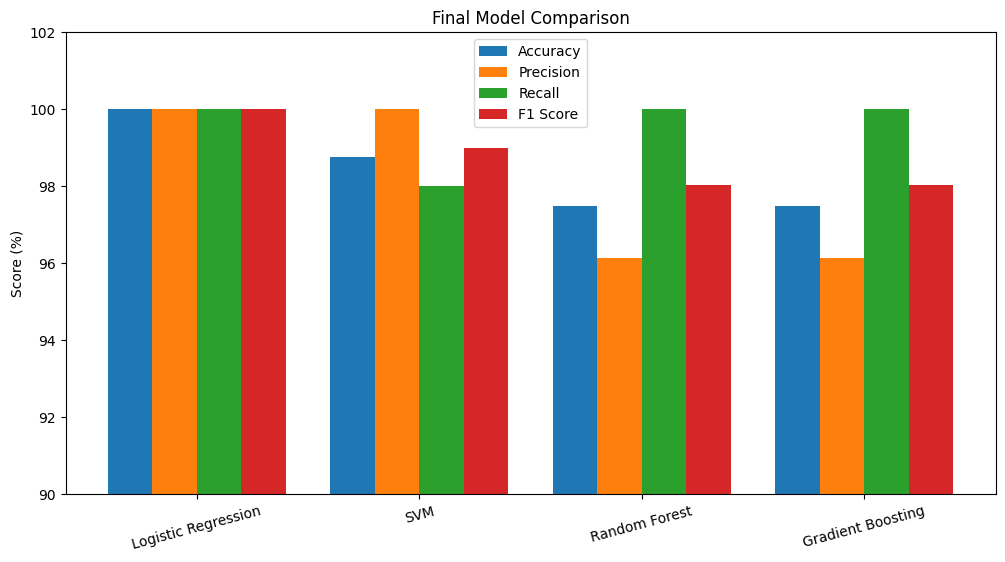

In [52]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Logistic Regression', 'SVM', 'Random Forest', 'Gradient Boosting']

accuracy = [100, 98.75, 97.5, 97.5]
precision = [100, 100, 96.15, 96.15]
recall = [100, 98, 100, 100]
f1 = [100, 98.99, 98.04, 98.04]

x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(12, 6))

plt.bar(x - 1.5*width, accuracy, width, label='Accuracy')
plt.bar(x - 0.5*width, precision, width, label='Precision')
plt.bar(x + 0.5*width, recall, width, label='Recall')
plt.bar(x + 1.5*width, f1, width, label='F1 Score')

plt.xticks(x, models, rotation=15)
plt.ylabel('Score (%)')
plt.title('Final Model Comparison')
plt.legend()
plt.ylim(90, 102)

plt.show()

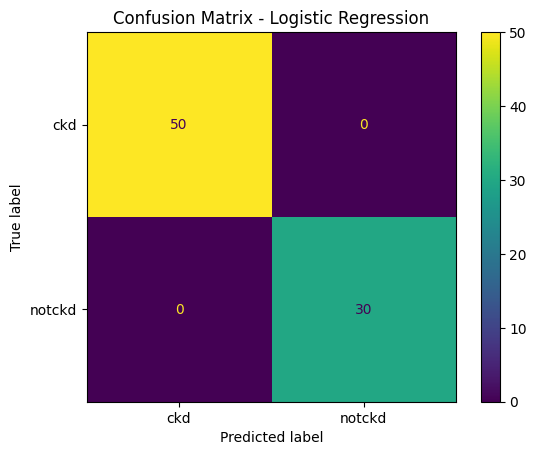

In [53]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ['ckd', 'notckd']

cm = confusion_matrix(y_test, y_pred_lr_final, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

**Model Deployment**

In [54]:
import joblib

joblib.dump(best_lr, 'ckd_model.pkl')


joblib.dump(scaler, 'scaler.pkl')

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [55]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 72.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 54.6 MB/s eta 0:00:00


In [56]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

In [57]:
import subprocess, time, re

subprocess.Popen(["streamlit", "run", "app.py",
                  "--server.port", "8501", "--server.headless", "true"])

log = open("tunnel.log", "w")
subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                 stdout=log, stderr=log)

time.sleep(8)
print(re.findall(r"https://[a-z0-9-]+\.trycloudflare\.com", open("tunnel.log").read()))

['https://witch-only-connected-bird.trycloudflare.com']


In [58]:
!pkill -f streamlit
import subprocess, time

log = open("streamlit.log", "w")
subprocess.Popen(["streamlit", "run", "app.py",
                  "--server.port", "8501", "--server.headless", "true"],
                 stdout=log, stderr=log)
time.sleep(8)

print(open("streamlit.log").read())
!curl -s -o /dev/null -w "HTTP %{http_code}\n" http://localhost:8501



2026-10-10 09:48:46.887 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.90.42.26:8501


HTTP 200
